# Exploring the cardiac data

A simple exploration of the training data described in `README.md`: demographics
and cardiac point clouds at 10 points in the cardiac cycle.

We will look at group sizes, age, BMI, blood pressure, and example heart shapes.
We use the labels `healthy` and `pMI` exactly as stored in the data.

**Setup:** select the project's `.venv` Python kernel so the package and its
NumPy, pandas, and Matplotlib dependencies are available.
Run the cells below in order. Keep the supplied data under
`data/training_data/` (the data directory is ignored by Git).


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from introml_myocardial_infarction import CardiacDataLoader

# Locate the project whether Jupyter starts in the repository or notebooks folder.
project_root = Path.cwd()
if not (project_root / "pyproject.toml").is_file():
    project_root = project_root.parent

data_dir = project_root / "data" / "training_data"

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})
groups = ["healthy", "pMI"]
colors = {"healthy": "tab:blue", "pMI": "tab:orange"}


## 1. Read the demographics

`CardiacDataLoader` reads the existing training folder. Its `demographics`
DataFrame contains the original columns, indexed by sample ID. Point clouds
are loaded only when requested.


In [3]:
loader = CardiacDataLoader(data_dir)
demographics = loader.demographics
demographics.index.name = "sample_id"

print(f"Demographic rows: {len(loader)}")
print(f"Point cloud files: {len(list(loader.samples_dir.glob('*.npy')))}")
demographics.head()


Demographic rows: 900
Point cloud files: 900


,MI,age,BMI,height,weight,diastolic_BP,systolic_BP,sex
sample_id,,,,,,,,
0,healthy,62.593012,25.312186,161.647749,64.949107,76.057670,137.765801,False
1,healthy,58.037959,32.100795,172.543391,94.715477,84.272113,143.459426,False
2,pMI,65.840496,26.099055,166.521430,71.650562,75.340419,137.100866,False
3,pMI,68.518300,27.672836,166.176884,75.779414,75.697258,140.518093,True
4,healthy,55.591381,27.266429,161.314821,70.185424,79.973837,133.740780,False


In [4]:
# Check missing values before comparing distributions.
pd.DataFrame({
    "dtype": demographics.dtypes.astype(str),
    "missing_values": demographics.isna().sum(),
})

,dtype,missing_values
MI,str,0
age,float64,0
BMI,float64,0
height,float64,0
weight,float64,0
diastolic_BP,float64,0
systolic_BP,float64,0
sex,bool,0


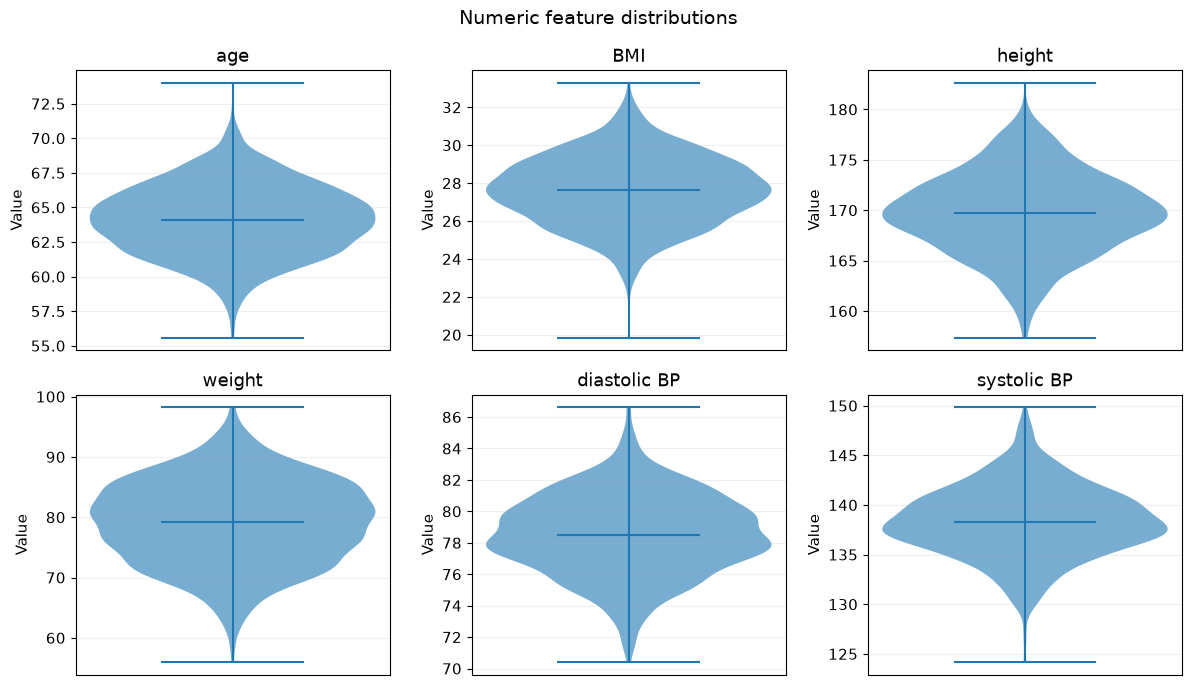

In [5]:
# Distributions of all numeric features in one figure.
# Separate axes preserve each feature's original scale.
# Horizontal lines show the mean, minimum, and maximum.
numeric_features = demographics.select_dtypes(include="number")
ncols = 3
nrows = (len(numeric_features.columns) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.5 * nrows), squeeze=False)

for ax, column in zip(axes.flat, numeric_features.columns):
    values = numeric_features[column].dropna().to_numpy()
    violin = ax.violinplot(values, showmeans=True, showextrema=True)
    for body in violin["bodies"]:
        body.set_facecolor("tab:blue")
        body.set_alpha(0.6)
    ax.set_title(column.replace("_", " "))
    ax.set_ylabel("Value")
    ax.set_xticks([])
    ax.grid(axis="y", alpha=0.2)

for ax in axes.flat[len(numeric_features.columns):]:
    ax.set_visible(False)

fig.suptitle("Numeric feature distributions", fontsize=14)
fig.tight_layout()
plt.show()


## 2. How many samples are in each group?

Group sizes help us see whether one label dominates the dataset.
The README does not define the Boolean sex coding, so we keep its original values.

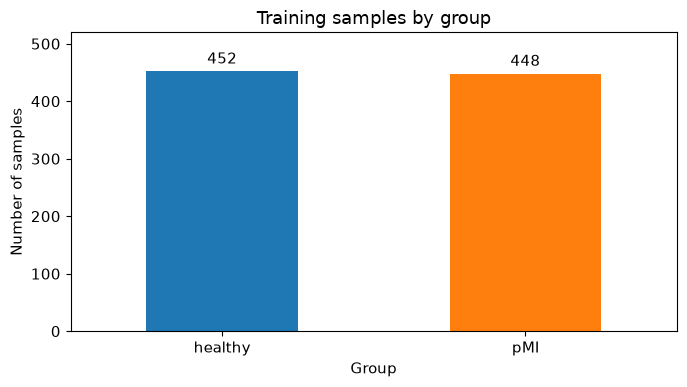

sex,False,True
MI,,
healthy,250,202
pMI,88,360


In [6]:
group_counts = demographics["MI"].value_counts().reindex(groups, fill_value=0)
ax = group_counts.plot.bar(color=[colors[group] for group in groups], rot=0)
ax.set(title="Training samples by group", xlabel="Group", ylabel="Number of samples")
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(0, group_counts.max() * 1.15)
plt.tight_layout()
plt.show()

pd.crosstab(demographics["MI"], demographics["sex"]).reindex(groups)

## 3. Demographic distributions

Compare age, BMI, and the blood pressure measurements taken at imaging.
Each panel uses the same histogram bins for both groups. These are descriptive
comparisons; differences here do not establish a cause or a diagnosis.

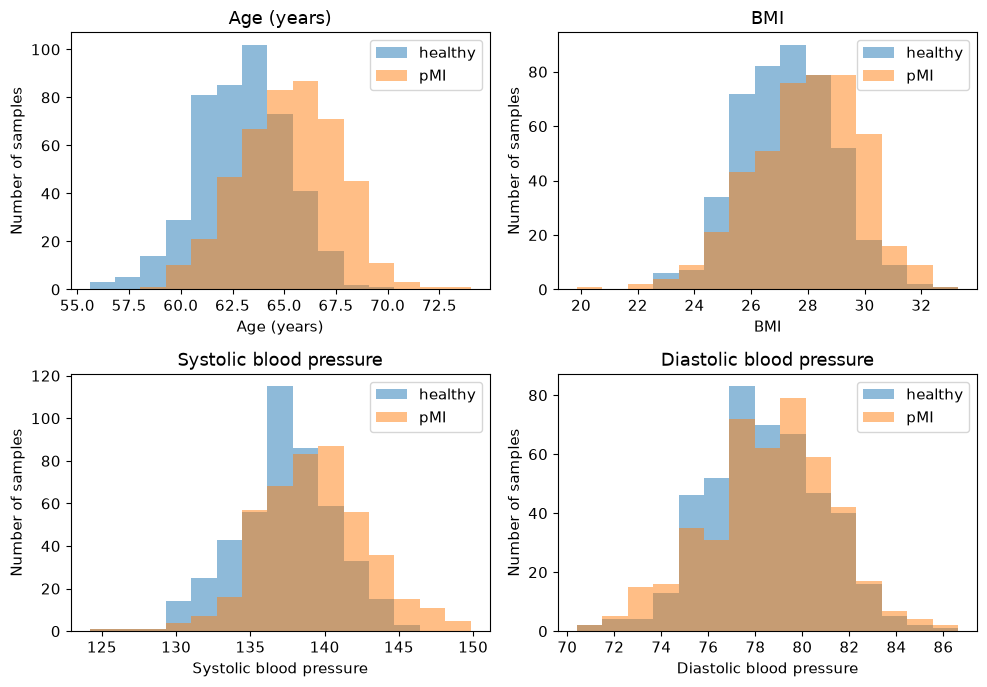

In [7]:
measurements = {
    "age": "Age (years)",
    "BMI": "BMI",
    "systolic_BP": "Systolic blood pressure",
    "diastolic_BP": "Diastolic blood pressure",
}

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (column, label) in zip(axes.flat, measurements.items()):
    bins = np.histogram_bin_edges(demographics[column].dropna(), bins=15)
    for group in groups:
        values = demographics.loc[demographics["MI"] == group, column].dropna()
        ax.hist(values, bins=bins, alpha=0.5, color=colors[group], label=group)
    ax.set(xlabel=label, ylabel="Number of samples", title=label)
    ax.legend()

fig.tight_layout()
plt.show()

In [8]:
# Numerical context for the plots: average values in each group.
demographics.groupby("MI")[list(measurements)].mean().round(2)

,age,BMI,systolic_BP,diastolic_BP
MI,,,,
healthy,62.97,27.29,137.37,78.4
pMI,65.26,27.96,139.29,78.6


## 4. Example point clouds across the cardiac cycle

Load the first sample in each group. Each array has shape
`(frames, points, columns)`: the first three columns are the coordinates and the
fourth contains point labels `0`, `1`, and `2`. The README does not identify the
anatomical meaning of these labels, so we show their stored codes.

Compare frames 0 and 5, which are halfway through the supplied 10-frame sequence
from each other. Their exact cardiac phase names are not provided.
We plot every tenth point for readability and use the same coordinate limits
across all four panels. These two samples are examples, not group averages.

In [9]:
example_clouds = {}
for group in groups:
    sample_id = demographics.index[demographics["MI"] == group][0]
    example_clouds[group] = loader.load_point_cloud(sample_id)
    print(f"{group}, sample {sample_id}: {example_clouds[group].shape}")


healthy, sample 0: (10, 18000, 4)
pMI, sample 2: (10, 18000, 4)


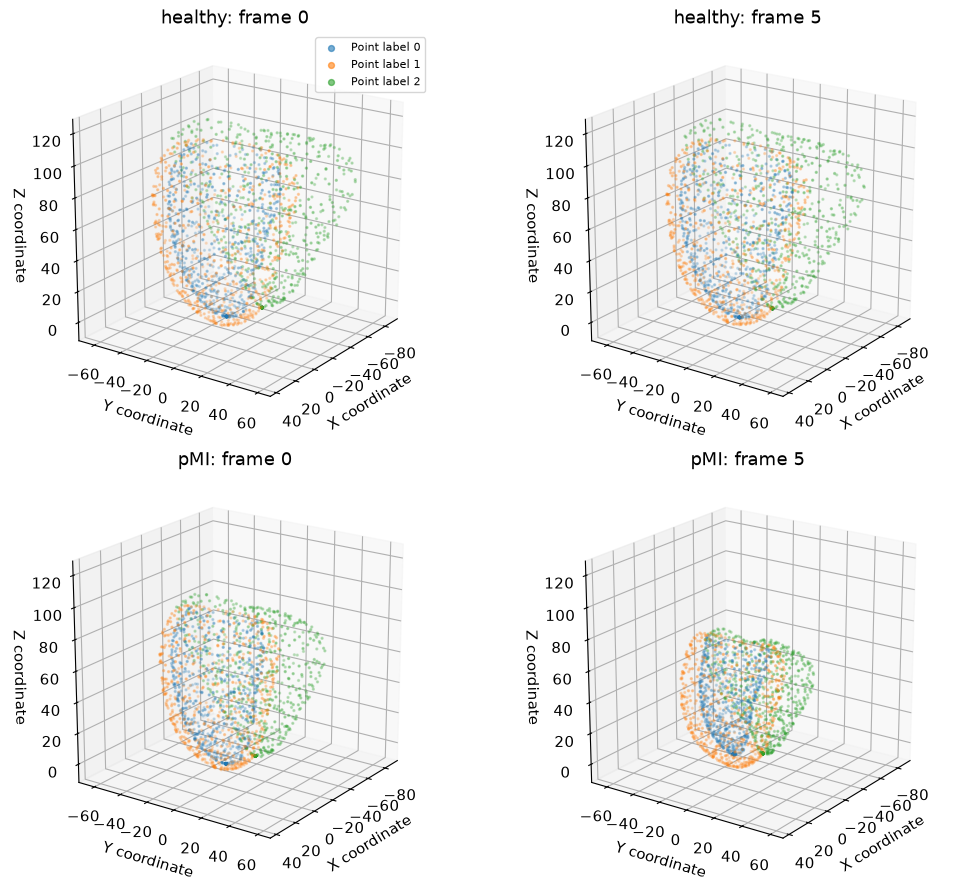

In [10]:
frames = [0, 5]
point_colors = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}

# Shared limits and equal axis scaling make shape comparisons easier.
all_coordinates = np.concatenate([
    cloud[frames, :, :3].reshape(-1, 3) for cloud in example_clouds.values()
])
center = (all_coordinates.min(axis=0) + all_coordinates.max(axis=0)) / 2
half_width = np.ptp(all_coordinates, axis=0).max() / 2 * 1.05

fig = plt.figure(figsize=(11, 9))
for row, group in enumerate(groups):
    for col, frame in enumerate(frames):
        ax = fig.add_subplot(2, 2, row * 2 + col + 1, projection="3d")
        points = example_clouds[group][frame, ::10, :]
        for point_label, color in point_colors.items():
            subset = points[points[:, 3] == point_label, :3]
            ax.scatter(*subset.T, s=2, alpha=0.6, color=color,
                       label=f"Point label {point_label}")
        ax.set(title=f"{group}: frame {frame}",
               xlabel="X coordinate", ylabel="Y coordinate", zlabel="Z coordinate",
               xlim=(center[0] - half_width, center[0] + half_width),
               ylim=(center[1] - half_width, center[1] + half_width),
               zlim=(center[2] - half_width, center[2] + half_width))
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(elev=20, azim=35)
        if row == 0 and col == 0:
            ax.legend(markerscale=3, fontsize=8)

fig.tight_layout()
plt.show()

## 5. Interactive 3D heart viewer

Drag to rotate the heart, scroll to zoom, and use the slider to select a frame.
Change `viewer_sample_id` to any ID in `demographics.index` and rerun the cell.
The slider uses frame indices because physical timestamps are not supplied.

[Plotly](https://plotly.com/python/animations/) displays the original point clouds.
Colours identify the stored surface codes; the axis scale stays fixed across frames.
If the geometry-processing [PyMesh](https://pymesh.readthedocs.io/en/latest/basic.html)
is available, its mesh objects hold the vertices before display. Otherwise the
viewer uses the NumPy coordinates directly. The `pymesh` 1.0.2 package from PyPI
is a different project and does not provide `form_mesh`.

**Setup:** install Plotly in the notebook environment with `%pip install plotly`.
The viewer embeds its JavaScript and does not require `nbformat` or a widget extension.


In [12]:
import plotly.graph_objects as go
from IPython.display import HTML, display

try:
    import pymesh
except ImportError:
    pymesh = None

form_mesh = getattr(pymesh, "form_mesh", None)
if form_mesh is None:
    print("PyMesh's geometry API is unavailable; displaying the original points with Plotly.")

viewer_sample_id = demographics.index[0]  # Change this to explore another heart.
viewer_cloud = loader.load_point_cloud(viewer_sample_id)
point_stride = 3  # Use 1 to display every point.
viewer_colors = {0: "royalblue", 1: "orange", 2: "seagreen"}


def heart_traces(frame_index):
    points = viewer_cloud[frame_index]
    traces = []
    for surface_code, color in viewer_colors.items():
        vertices = points[points[:, 3] == surface_code, :3][::point_stride]
        if form_mesh is not None:
            mesh = form_mesh(
                np.ascontiguousarray(vertices), np.empty((0, 3), dtype=np.int32)
            )
            vertices = mesh.vertices
        traces.append(go.Scatter3d(
            x=vertices[:, 0], y=vertices[:, 1], z=vertices[:, 2],
            mode="markers", name=f"Surface code {surface_code}",
            marker=dict(size=2, color=color, opacity=0.8),
        ))
    return traces


# Bound all frames together to keep the heart's scale fixed as time changes.
viewer_xyz = viewer_cloud[..., :3].reshape(-1, 3)
viewer_min = viewer_xyz.min(axis=0)
viewer_max = viewer_xyz.max(axis=0)
viewer_padding = (viewer_max - viewer_min).max() * 0.05
viewer_limits = np.column_stack((
    viewer_min - viewer_padding, viewer_max + viewer_padding
))
viewer_frames = [
    go.Frame(name=str(t), data=heart_traces(t), traces=[0, 1, 2])
    for t in range(viewer_cloud.shape[0])
]
heart_viewer = go.Figure(data=viewer_frames[0].data, frames=viewer_frames)
heart_viewer.update_layout(
    title=f"Heart sample {viewer_sample_id}", height=650,
    margin=dict(l=0, r=0, t=50, b=60),
    scene=dict(
        xaxis=dict(title="X", range=viewer_limits[0].tolist(), autorange=False),
        yaxis=dict(title="Y", range=viewer_limits[1].tolist(), autorange=False),
        zaxis=dict(title="Z", range=viewer_limits[2].tolist(), autorange=False),
        aspectmode="data", uirevision="heart-camera",
    ),
    sliders=[dict(
        active=0, currentvalue=dict(prefix="Frame: "),
        steps=[dict(
            label=str(t), method="animate",
            args=[[str(t)], dict(
                mode="immediate", frame=dict(duration=0, redraw=True),
                transition=dict(duration=0),
            )],
        ) for t in range(viewer_cloud.shape[0])],
    )],
)
display(HTML(heart_viewer.to_html(full_html=False, include_plotlyjs=True)))


PyMesh's geometry API is unavailable; displaying the original points with Plotly.


## What to look for

- Are the groups similar in size?
- How much do the age, BMI, and blood pressure distributions overlap?
- How does each example's shape change between frames 0 and 5?

The demographic summaries describe the training set. The shape plots show only
two individuals; a broader comparison would need more samples and defined shape
measurements. The MRI resolution in the README does not by itself establish the
coordinate units of the reconstructed point clouds.